In [82]:
from typing import TypedDict,Literal
from langgraph.graph import StateGraph,START,END


In [83]:
class Equationstate(TypedDict):
    a:int
    b:int
    c:int

    equation:str
    discriminant:float
    result:str


In [84]:
def show_equation(state:Equationstate):
    equation=f"{state["a"]}x^2 + ({state['b']}x) + {state['c']}"

    return {"equation":equation}

In [85]:
def calculate_discriminant(state:Equationstate):
    discriminant=(state['b']**2 )-(4*state['a']*state["c"])

    return {"discriminant":discriminant}

In [86]:
def no_real_roots(state:Equationstate):

    result=f"Thre are no real roots "

    return {"result":result}

In [87]:
def real_roots(state:Equationstate):
    
    root1=(-state["b"]+state["discriminant"]**0.5)/(2*state["a"])
    root2=(-state["b"]-state["discriminant"]**0.5)/(2*state["a"])

    result=f"The roots are {root1} and {root2}"

    return {"result":result}
    

In [88]:
def repeated_roots(state:Equationstate):
    
    root=(-state["b"])/(2*state["a"])

    result=f"The roots are {-root} and {+root} "

    return {"result":result}

In [89]:
def check_condition(state:Equationstate)->Literal["real_roots","no_real_roots","repeated_roots"]:
    if state["discriminant"]>0:
        return "real_roots"
    elif state["discriminant"]==0:
        return "repeated_roots"
    else :
        return "no_real_roots"

In [90]:
graph=StateGraph(Equationstate)

graph.add_node("show_equation",show_equation)
graph.add_node("calculate_discriminant",calculate_discriminant)
graph.add_node("no_real_roots",no_real_roots)
graph.add_node("repeated_roots",repeated_roots)
graph.add_node("real_roots",real_roots)

graph.add_edge(START,"show_equation")
graph.add_edge("show_equation","calculate_discriminant")

graph.add_conditional_edges("calculate_discriminant",check_condition)

graph.add_edge("real_roots",END)
graph.add_edge("repeated_roots",END)
graph.add_edge("no_real_roots",END)



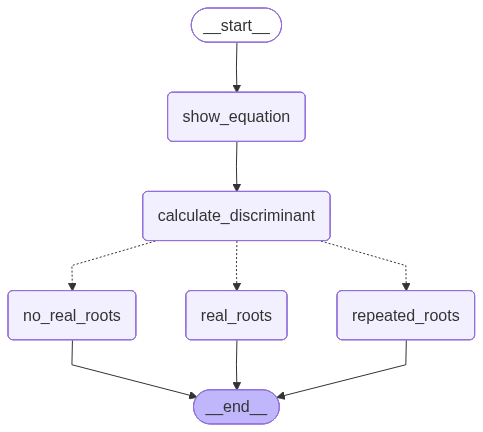

In [91]:
workflow=graph.compile()
workflow

In [94]:
intial_state={
    "a":3,
    "b":6,
    "c":3}

workflow.invoke(intial_state)

{'a': 3,
 'b': 6,
 'c': 3,
 'equation': '3x^2 + (6x) + 3',
 'discriminant': 0,
 'result': 'The roots are 1.0 and -1.0 '}